## Data retrieval

In [1]:
import cdsapi

dataset = "reanalysis-era5-single-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["sea_surface_temperature"],
    "year": [
        "1950", "1951", "1952",
        "1953", "1954", "1955",
        "1956", "1957", "1958",
        "1959", "1960", "1961",
        "1962", "1963", "1964",
        "1965", "1966", "1967",
        "1968", "1969", "1970",
        "1971", "1972", "1973",
        "1974", "1975", "1976",
        "1977", "1978", "1979",
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987", "1988",
        "1989", "1990", "1991",
        "1992", "1993", "1994",
        "1995", "1996", "1997",
        "1998", "1999", "2000",
        "2001", "2002", "2003",
        "2004", "2005", "2006",
        "2007", "2008", "2009",
        "2010", "2011", "2012",
        "2013", "2014", "2015",
        "2016", "2017", "2018",
        "2019", "2020", "2021",
        "2022", "2023", "2024",
        "2025"
    ],
    "month": [
        "01", "02", "09",
        "10", "11", "12"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "06:00", "12:00",
        "18:00"
    ],
    "grid": "1.0/1.0",
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [5, -170, -5, -120]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()


2026-04-16 21:33:38,620 INFO [2025-12-11T00:00:00] Please note that a dedicated catalogue entry for this dataset, post-processed and stored in Analysis Ready Cloud Optimized (ARCO) format (Zarr), is available for optimised time-series retrievals (i.e. for retrieving data from selected variables for a single point over an extended period of time in an efficient way). You can discover it [here](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries?tab=overview)
2026-04-16 21:33:38,624 INFO Request ID is 29387074-f5fe-4f42-9236-e3a7f7cec029
2026-04-16 21:33:38,707 INFO status has been updated to accepted
2026-04-16 21:33:52,499 INFO status has been updated to running
Recovering from connection error [HTTPSConnectionPool(host='cds.climate.copernicus.eu', port=443): Max retries exceeded with url: /api/retrieve/v1/jobs/29387074-f5fe-4f42-9236-e3a7f7cec029?log=True&request=True (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x000002

5f3822040ecdf17a3834e19f3302d6a8.grib:   0%|          | 0.00/66.9M [00:00<?, ?B/s]

'5f3822040ecdf17a3834e19f3302d6a8.grib'

## Index calculation

In [1]:
import xarray as xr
from datetime import datetime, date
import numpy as np

In [2]:
ds = xr.load_dataset("ERA5_features/grib_files/nino34_sst.grib", engine="cfgrib")

Ignoring index file 'ERA5_features/grib_files/nino34_sst.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
nino34_sst = ds.sst.reset_coords(['number', 'step', 'surface', 'valid_time'], drop=True)

In [4]:
nino34_sst = nino34_sst.sel(time=slice("1950-07", "2025-06"))

In [5]:
enso_hourly = nino34_sst.mean(dim=['longitude', 'latitude'])

In [6]:
enso_daily = enso_hourly.sel(time=(enso_hourly.time.dt.hour == 0))

In [7]:
enso_daily = enso_daily.sel(time=~(((enso_daily.time.dt.month == 2) & (enso_daily.time.dt.day == 29)) | (enso_daily.time.dt.month == 9)))

In [8]:
enso_seasonmean = enso_daily.coarsen(time=151).construct(time=("year", "date")).mean(dim='date')

In [9]:
train_data = enso_seasonmean[:60]
fit_params = np.polyfit(train_data.year, train_data, 1)
linear_fit_extrap = fit_params[0]*enso_seasonmean.year + fit_params[1]

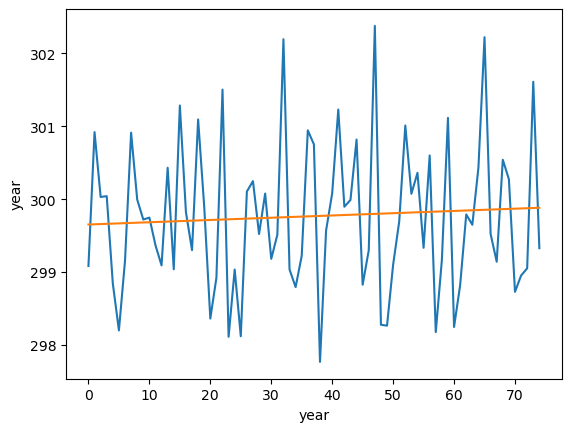

In [10]:
enso_seasonmean.plot()
linear_fit_extrap.plot()

In [11]:
enso_dailyanom = enso_daily.coarsen(time=151).construct(time=("year", "date")) - linear_fit_extrap
enso_dailyanom = enso_dailyanom.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)

In [12]:
import pandas as pd
from datetime import timedelta

In [13]:
df_enso = enso_dailyanom.to_dataframe(name='sst')

In [14]:
df_enso['sst_rolling_mean'] = df_enso['sst'].rolling(window=timedelta(days=7), min_periods=7).mean()

In [15]:
df_enso = df_enso.drop(['sst'], axis=1)
df_enso = df_enso.rename(columns={'sst_rolling_mean':'nino3.4_index'})
df_enso = df_enso.dropna()

In [16]:
month = df_enso.index.month
day = df_enso.index.day
df_enso_week3 = df_enso[((month == 11) & (day >= 16)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 7))]

<Axes: xlabel='time'>

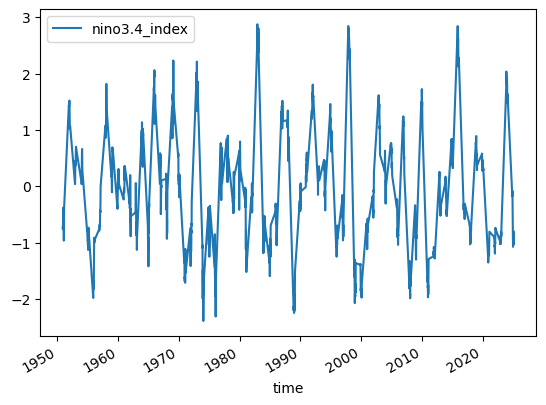

In [17]:
df_enso_week3.plot()

In [18]:
df_enso_week3

,nino3.4_index
time,
1950-11-16,-0.733530
1950-11-17,-0.740593
1950-11-18,-0.747202
1950-11-19,-0.752878
1950-11-20,-0.757177
...,...
2025-02-03,-0.934708
2025-02-04,-0.909339
2025-02-05,-0.878900


In [19]:
df_enso_week3.to_csv('ENSO_week3.csv')

In [19]:
month = df_enso.index.month
day = df_enso.index.day
df_enso_week4 = df_enso[((month == 11) & (day >= 9)) | (month == 12) | (month == 1)]
df_enso_week5 = df_enso[((month == 11) & (day >= 2)) | (month == 12) | ((month == 1) & (day <= 24))]
df_enso_week6 = df_enso[((month == 10) & (day >= 26)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 17))]
df_enso_week7 = df_enso[((month == 10) & (day >= 19)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 10))]
df_enso_week7

,nino3.4_index
time,
1950-10-19,-0.559423
1950-10-20,-0.560522
1950-10-21,-0.563591
1950-10-22,-0.568182
1950-10-23,-0.573840
...,...
2025-01-06,-0.930035
2025-01-07,-0.912330
2025-01-08,-0.900180


In [19]:
df_enso_week4.to_csv('ENSO_week4.csv')
df_enso_week5.to_csv('ENSO_week5.csv')

In [20]:
df_enso_week6.to_csv('ENSO_week6.csv')
df_enso_week7.to_csv('ENSO_week7.csv')